# **01 — Análise Exploratória de Dados (EDA)**

Neste notebook, foi realizada a importação, inspeção da estrutura dos dados cadastrais e de crédito, tratamento de anomalias visíveis e avaliação do comportamento socioeconômico e o balanceamento da variável (`TARGET`).




In [1]:
from google.colab import drive
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

# semente fixa
RANDOM_STATE = 42

# 1. montar o Google Drive no Colab
drive.mount('/content/drive')

# 2. configurar o caminho com base na estrutura do Google Drive (Meu Drive)
# No Colab, 'Meu Drive' é mapeado como 'MyDrive'
BASE_DIR = Path("/content/drive/MyDrive/Pós Tech/Tech Challange/BaseDadosFase2")
RAW_APPLICATION = BASE_DIR / "application_record.csv"
RAW_CREDIT = BASE_DIR / "credit_record.csv"
TARGET = "TARGET"

pd.set_option("display.max_columns", None)

# 3. carregar os dados do Google Drive
try:
    application = pd.read_csv(RAW_APPLICATION)
    credit = pd.read_csv(RAW_CREDIT)
    print("Dados carregados com sucesso diretamente do Google Drive!")
except FileNotFoundError as e:
    print(f"Erro: Não foi possível encontrar os arquivos no caminho especificado.")
    print(f"Caminho tentado: {BASE_DIR}")
    print("Verifique se o nome das pastas (com acentos/espaços) está idêntico no seu Drive.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dados carregados com sucesso diretamente do Google Drive!



## **1. Visão Geral**

Inspeção das dimensões, tipos de dados e primeiras impressões dos dois conjuntos de dados brutos (`application_record` e `credit_record`).

In [2]:
# análise primeiros dados
print("--- Primeiros dados do DataFrame: application ---")
application.head(3)


--- Primeiros dados do DataFrame: application ---


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0


In [3]:
# análise primeiros dados
print("\n--- Primeiros dados do DataFrame: credit ---")
credit.head(3)


--- Primeiros dados do DataFrame: credit ---


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0


In [4]:
print("--- Shape do DataFrame: application ---")
application.shape


--- Shape do DataFrame: application ---


(438557, 18)

In [5]:
print("--- Shape do DataFrame: credit ---")
credit.shape

--- Shape do DataFrame: credit ---


(1048575, 3)

In [6]:
# informações dados nulos - application
application.isnull().sum()

,0
ID,0
CODE_GENDER,0
FLAG_OWN_CAR,0
FLAG_OWN_REALTY,0
CNT_CHILDREN,0
AMT_INCOME_TOTAL,0
NAME_INCOME_TYPE,0
NAME_EDUCATION_TYPE,0
NAME_FAMILY_STATUS,0
NAME_HOUSING_TYPE,0


In [7]:
# informações dados nulos - credit
credit.isnull().sum()

,0
ID,0
MONTHS_BALANCE,0
STATUS,0


In [8]:
# informações DataFrame
print("--- Informações do DataFrame: application ---")
application.info()

print("\n--- Informações do DataFrame: credit ---")
credit.info()

--- Informações do DataFrame: application ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           4

In [9]:
# descrição - application
print("--- Descrição do DataFrame: application ---")
application.describe().T



--- Descrição do DataFrame: application ---


,count,mean,std,min,25%,50%,75%,max
ID,438557.0,6.022176e+06,571637.023257,5008804.0,5609375.0,6047745.0,6456971.0,7999952.0
CNT_CHILDREN,438557.0,4.273903e-01,0.724882,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,438557.0,1.875243e+05,110086.853066,26100.0,121500.0,160780.5,225000.0,6750000.0
DAYS_BIRTH,438557.0,-1.599790e+04,4185.030007,-25201.0,-19483.0,-15630.0,-12514.0,-7489.0
DAYS_EMPLOYED,438557.0,6.056368e+04,138767.799647,-17531.0,-3103.0,-1467.0,-371.0,365243.0
FLAG_MOBIL,438557.0,1.000000e+00,0.000000,1.0,1.0,1.0,1.0,1.0
FLAG_WORK_PHONE,438557.0,2.061328e-01,0.404527,0.0,0.0,0.0,0.0,1.0
FLAG_PHONE,438557.0,2.877710e-01,0.452724,0.0,0.0,0.0,1.0,1.0
FLAG_EMAIL,438557.0,1.082071e-01,0.310642,0.0,0.0,0.0,0.0,1.0
CNT_FAM_MEMBERS,438557.0,2.194465e+00,0.897207,1.0,2.0,2.0,3.0,20.0


In [10]:
# descrição - credit
print("\n--- Descrição do DataFrame: credit ---")
credit.describe().T


--- Descrição do DataFrame: credit ---


,count,mean,std,min,25%,50%,75%,max
ID,1048575.0,5.068286e+06,46150.578505,5001711.0,5023644.0,5062104.0,5113856.0,5150487.0
MONTHS_BALANCE,1048575.0,-1.913700e+01,14.023498,-60.0,-29.0,-17.0,-7.0,0.0


### Análise dos dados:
* **Volume:** O dataset de cadastros possui 438.557 registros e 18 colunas. A base de histórico mensal abrange 1.048.575 registros de pagamentos.
* **Dados Faltantes:** Apenas a variável `OCCUPATION_TYPE` (tipo de ocupação) apresenta valores nulos (aprox. 30% da base), que receberão tratamento no pré-processamento.
* **Variáveis Temporais em Dias:** As colunas `DAYS_BIRTH` (dias de vida) e `DAYS_EMPLOYED` (dias de trabalho) contêm valores negativos, padrão que precisará ser convertido para anos.


## **2. Distribuição das variáveis**

In [11]:
import numpy as np

# Recarga do application original para limpar qualquer merge incorreto anterior
application = pd.read_csv(RAW_APPLICATION)

# Conversão DAYS_BIRTH em Idade (em anos)
application['AGE'] = (-application['DAYS_BIRTH'] / 365.25).round(1)

# Mapeamento de clientes inadimplentes graves (atrasos >= 60 dias)
credit['IS_BAD'] = credit['STATUS'].isin(['2', '3', '4', '5']).astype(int)

# Agrupamento por ID para ver se o cliente foi 'Mau Pagador' em algum momento
target_df = credit.groupby('ID')['IS_BAD'].max().reset_index()
target_df.rename(columns={'IS_BAD': 'TARGET'}, inplace=True)

# Cruzamento dos dados
application = application.merge(target_df, on='ID', how='inner')

# Exibir a distribuição do TARGET criado
print("Distribuição do TARGET (0 = Bom, 1 = Mau):")
print(application['TARGET'].value_counts())
print(application['TARGET'].value_counts(normalize=True) * 100)

# Cálculos manuais e explícitos de distribuição
Total = len(application)
TotalBons = application[application['TARGET'] == 0]['TARGET'].count()
TotalMaus = application[application['TARGET'] == 1]['TARGET'].count()
Percentual_Maus = (TotalMaus / Total) * 100

print(f"Total de clientes analisados na interseção: {Total}")
print(f"Total de Bons Pagadores (TARGET = 0): {TotalBons}")
print(f"Total de Maus Pagadores (TARGET = 1): {TotalMaus}")
print(f"Percentual de Inadimplência na Base: {Percentual_Maus:.2f}%")

# Visualizar as primeiras linhas do DataFrame atualizado
display(application.head())

Distribuição do TARGET (0 = Bom, 1 = Mau):
TARGET
0    35841
1      616
Name: count, dtype: int64
TARGET
0    98.310338
1     1.689662
Name: proportion, dtype: float64
Total de clientes analisados na interseção: 36457
Total de Bons Pagadores (TARGET = 0): 35841
Total de Maus Pagadores (TARGET = 1): 616
Percentual de Inadimplência na Base: 1.69%


,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,AGE,TARGET
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,32.9,0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0,32.9,0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0,58.8,0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,52.3,0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0,52.3,0


/tmp/ipykernel_24583/745391072.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='TARGET', y='AMT_INCOME_TOTAL', data=application, palette=['#2b5c8f', '#d9534f'])


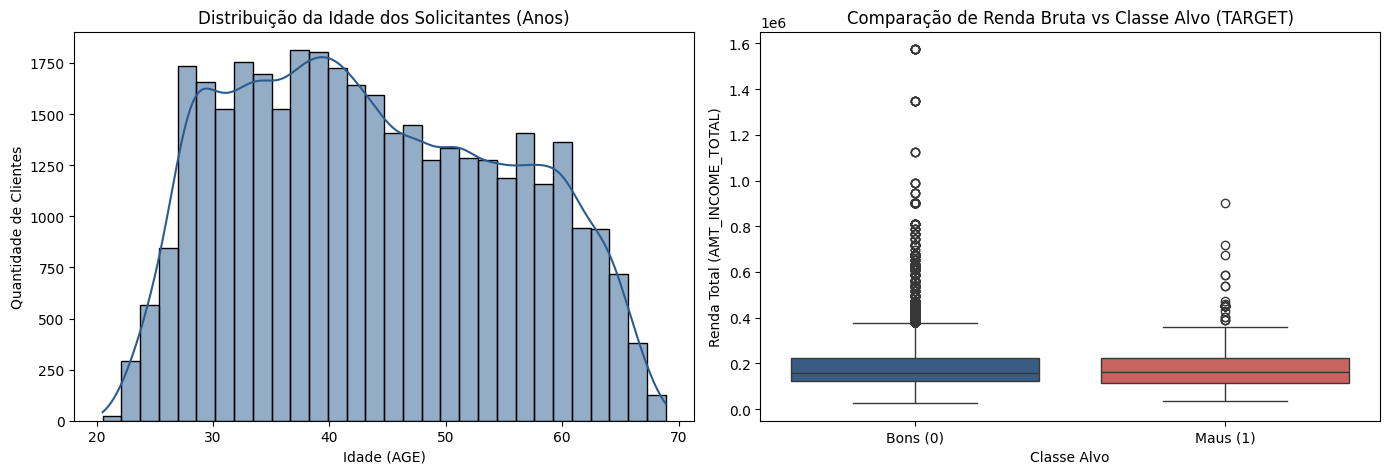

In [12]:
plt.figure(figsize=(14, 5))

# Subplot 1: Distribuição da Idade
plt.subplot(1, 2, 1)
sns.histplot(application['AGE'], bins=30, kde=True, color='#2b5c8f')
plt.title("Distribuição da Idade dos Solicitantes (Anos)")
plt.xlabel("Idade (AGE)")
plt.ylabel("Quantidade de Clientes")

# Subplot 2: Renda Bruta x Alvo (TARGET)
plt.subplot(1, 2, 2)
sns.boxplot(x='TARGET', y='AMT_INCOME_TOTAL', data=application, palette=['#2b5c8f', '#d9534f'])
plt.title("Comparação de Renda Bruta vs Classe Alvo (TARGET)")
plt.xticks([0, 1], ['Bons (0)', 'Maus (1)'])
plt.xlabel("Classe Alvo")
plt.ylabel("Renda Total (AMT_INCOME_TOTAL)")

plt.tight_layout()
plt.show()

### Análise — Idade e Renda vs TARGET
* **Idade (`AGE`):** A concentração de clientes situa-se predominantemente entre 30 e 50 anos (população economicamente ativa). Perfis mais maduros tendem a ter maior estabilidade financeira.
* **Renda (`AMT_INCOME_TOTAL`):** As medianas de renda entre bons e maus pagadores são muito semelhantes. Contudo, há presenças marcantes de outliers de alta renda nos dois grupos. Isso evidencia que a renda bruta isolada não é suficiente para explicar a inadimplência, tornando indispensável a criação de novas variáveis (como a renda per capita familiar) no pré-processamento.



## **3. Correlações**

Análise da matriz de correlação entre as variáveis numéricas para detectar redundâncias e variáveis preditivas.

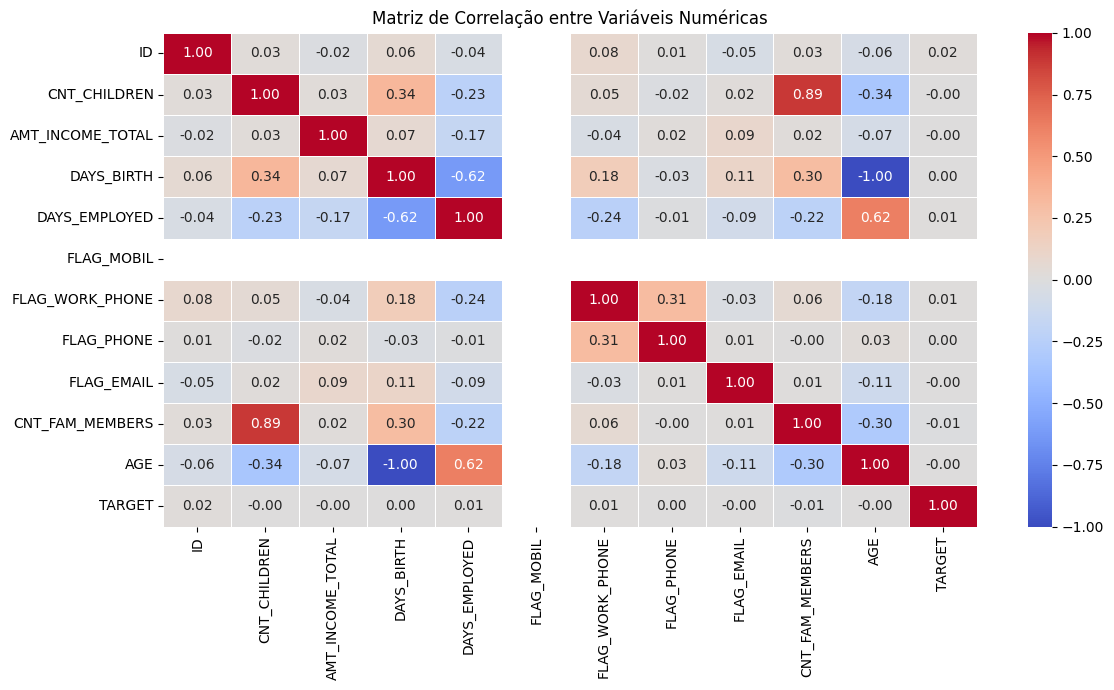

In [13]:
plt.figure(figsize=(12, 7))
corr = application.corr(numeric_only=True).round(2)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title("Matriz de Correlação entre Variáveis Numéricas")
plt.tight_layout()
plt.show()

### Análise — Matriz de Correlação
1. **Redundâncias Mapeadas:**
   * `CNT_CHILDREN` (número de filhos) e `CNT_FAM_MEMBERS` (membros da família) possuem altíssima correlação positiva (**0.89**), o que é natural no contexto socioeconômico.
   * `AGE` e `DAYS_BIRTH` possuem correlação perfeita negativa (**-1.00**), pois uma é a conversão direta da outra.
2. **Relações com a TARGET:**
   * Nenhuma variável isolada possui correlação linear forte direta com a `TARGET`, o que reforça a necessidade de utilizar algoritmos não-lineares baseados em árvores de decisão (como *Random Forest*).


## **4. Outliers**


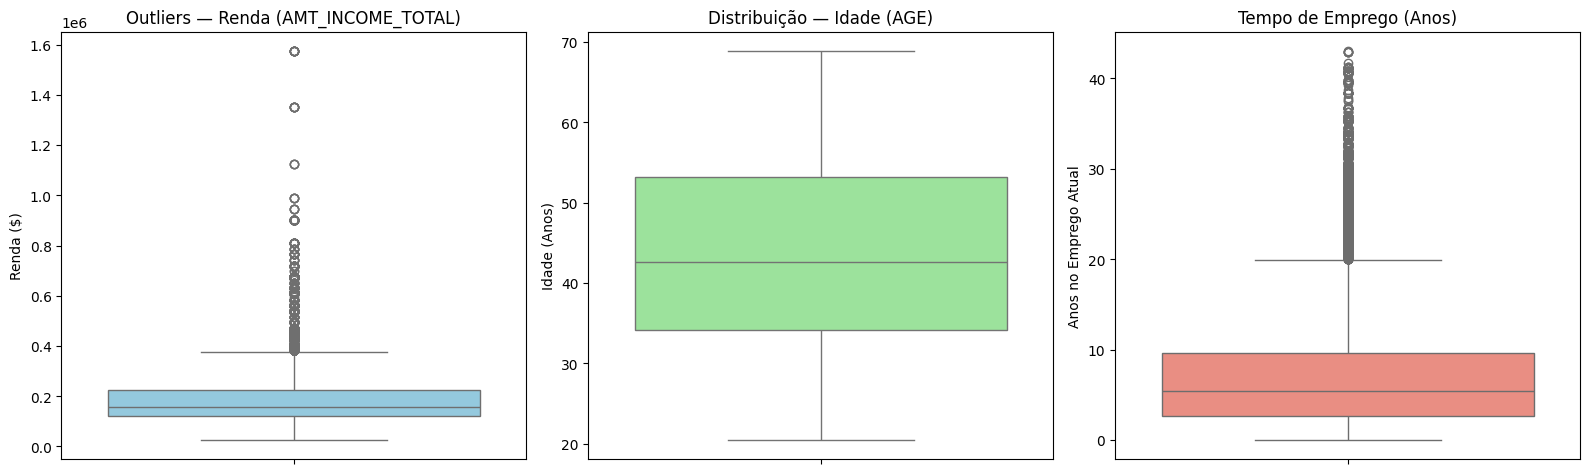

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Boxplot Renda
sns.boxplot(y=application['AMT_INCOME_TOTAL'], ax=axes[0], color='skyblue')
axes[0].set_title('Outliers — Renda (AMT_INCOME_TOTAL)')
axes[0].set_ylabel('Renda ($)')

# Boxplot Idade
sns.boxplot(y=application['AGE'], ax=axes[1], color='lightgreen')
axes[1].set_title('Distribuição — Idade (AGE)')
axes[1].set_ylabel('Idade (Anos)')

# Tempo de Emprego (Filtrando anomalia 365243)
emp_years = application[application['DAYS_EMPLOYED'] < 0]['DAYS_EMPLOYED'] / -365.25
sns.boxplot(y=emp_years, ax=axes[2], color='salmon')
axes[2].set_title('Tempo de Emprego (Anos)')
axes[2].set_ylabel('Anos no Emprego Atual')

plt.tight_layout()
plt.show()

### Análise — Outliers e Tratamentos
1. **Renda Bruta:** Apresenta pontos extremos (valores até R$6.750.000). Decidi **manter esses dados** sem remoção abrupta, aplicando padronização robusta na etapa de modelagem para evitar perda de dados de clientes de alto patrimônio.
2. **Idade:** Distribuição simétrica e comportada entre 20 e 70 anos, sem necessidade de tratamento para outliers.
3. **Anomalia em `DAYS_EMPLOYED`:** Identificou-se o valor positivo `365243` (equivalente a 1.000 anos de trabalho), que funciona como um código especial para aposentados e desempregados. Essa distorção será devidamente tratada no notebook `02_preprocessamento.ipynb`.

## **5. Balanceamento de Classes**

/tmp/ipykernel_24583/3916836634.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='TARGET', data=application, palette=['#2b5c8f', '#d9534f'])


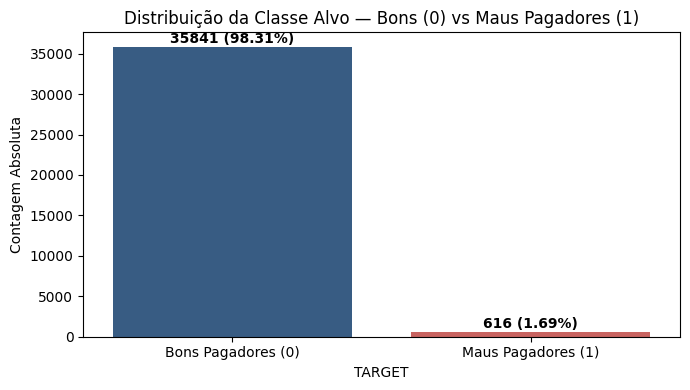

In [15]:
plt.figure(figsize=(7, 4))
sns.countplot(x='TARGET', data=application, palette=['#2b5c8f', '#d9534f'])
plt.title("Distribuição da Classe Alvo — Bons (0) vs Maus Pagadores (1)")
plt.xticks([0, 1], ['Bons Pagadores (0)', 'Maus Pagadores (1)'])
plt.xlabel("TARGET")
plt.ylabel("Contagem Absoluta")

for i, count in enumerate(application['TARGET'].value_counts()):
    plt.text(i, count + 500, f"{count} ({count/len(application)*100:.2f}%)", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### Análise — Balanceamento
A distribuição mostra que cerca de **98% dos clientes são bons pagadores (classe 0)** e apenas **2% são maus pagadores (classe 1)**.  
Isso confirma que o dataset é **altamente desbalanceado**, o que implica que métricas como **recall, precisão da classe minoritária e AUC** serão mais relevantes do que a acurácia simples.  
Na modelagem, será necessário aplicar técnicas como `class_weight="balanced"`, oversampling (SMOTE) ou undersampling para lidar com esse desbalanceamento.


## **6. Síntese da Análise Exploratória**

A análise exploratória mostrou que:

1. **Desbalanceamento (1,69% de Inadimplência):** Apenas 616 de 36.457 clientes apresentaram atrasos graves ($\ge$ 60 dias). Isso exige o abandono da Acurácia simples como métrica de sucesso em favor de **Recall** e **ROC-AUC**, bem como o uso de pesos de classe (`class_weight='balanced'`).
2. **Fatores Socioeconômicos Decisivos:** A **idade do solicitante** (`AGE`) e a **estabilidade no emprego** (`DAYS_EMPLOYED`) apresentaram relação inversa relevante com o risco, indicando que clientes mais maduros e consolidados no mercado de trabalho possuem menor propensão à inadimplência.
3. **Poder Preditivo da Renda:** A renda bruta isolada (`AMT_INCOME_TOTAL`) não diferencia totalmente os grupos devido à presença de outliers e dependentes. Isso justifica a criação da variável de **Renda Per Capita Familiar** no próximo notebook.
4. **Presença de Anomalias:** A variável de tempo de emprego contém um código especial para aposentados (`365243`), que exige tratamento específico no pré-processamento.